In [1]:
import sqlite3
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)


In [2]:
conn = sqlite3.connect(':memory:')

pd.read_csv(r'C:\Users\Acer\OneDrive\Desktop\online-shop\data\olist_orders_dataset.csv').to_sql('orders', conn, index=False)
pd.read_csv(r'C:\Users\Acer\OneDrive\Desktop\online-shop\data\olist_customers_dataset.csv').to_sql('customers', conn, index=False)
pd.read_csv(r'C:\Users\Acer\OneDrive\Desktop\online-shop\data\olist_order_payments_dataset.csv').to_sql('order_payments', conn, index=False)
pd.read_csv(r'C:\Users\Acer\OneDrive\Desktop\online-shop\data\olist_order_items_dataset.csv').to_sql('order_items', conn, index=False)

sql_query = """
WITH clean_orders AS (
    SELECT 
        o.order_id,
        c.customer_unique_id,
        c.customer_state,
        o.order_purchase_timestamp AS purchase_date,
        SUM(p.payment_value) AS total_revenue,
        SUM(i.freight_value) AS total_freight,
        COUNT(i.order_item_id) AS items_count
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN order_payments p ON o.order_id = p.order_id
    JOIN order_items i ON o.order_id = i.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY 1, 2, 3, 4
),
cohort_base AS (
    SELECT 
        *,
        MIN(strftime('%Y-%m-01', purchase_date)) OVER(PARTITION BY customer_unique_id) AS cohort_month,
        strftime('%Y-%m-01', purchase_date) AS order_month,
        ROW_NUMBER() OVER(PARTITION BY customer_unique_id ORDER BY purchase_date) AS order_num
    FROM clean_orders
)
SELECT 
    *,
    (CAST(strftime('%Y', order_month) AS INTEGER) - CAST(strftime('%Y', cohort_month) AS INTEGER)) * 12 +
    (CAST(strftime('%m', order_month) AS INTEGER) - CAST(strftime('%m', cohort_month) AS INTEGER)) AS cohort_index
FROM cohort_base;
"""

df = pd.read_sql_query(sql_query, conn)
print(f"Выгружено строк из SQL: {len(df)}")


Выгружено строк из SQL: 96477


In [3]:
initial_rows = len(df)

df['purchase_date'] = pd.to_datetime(df['purchase_date'])
df['cohort_month'] = pd.to_datetime(df['cohort_month'])
df['order_month'] = pd.to_datetime(df['order_month'])

df = df.drop_duplicates(subset=['order_id'])
df = df[(df['total_revenue'] > 0) & (df['total_freight'] >= 0)]

q99 = df['total_revenue'].quantile(0.99)
df_clean = df[df['total_revenue'] <= q99].copy()

print(f"Было строк: {initial_rows} | Стало: {len(df_clean)}")
print(f"Потеряно данных при очистке: {(1 - len(df_clean)/initial_rows):.2%}")


Было строк: 96477 | Стало: 95514
Потеряно данных при очистке: 1.00%


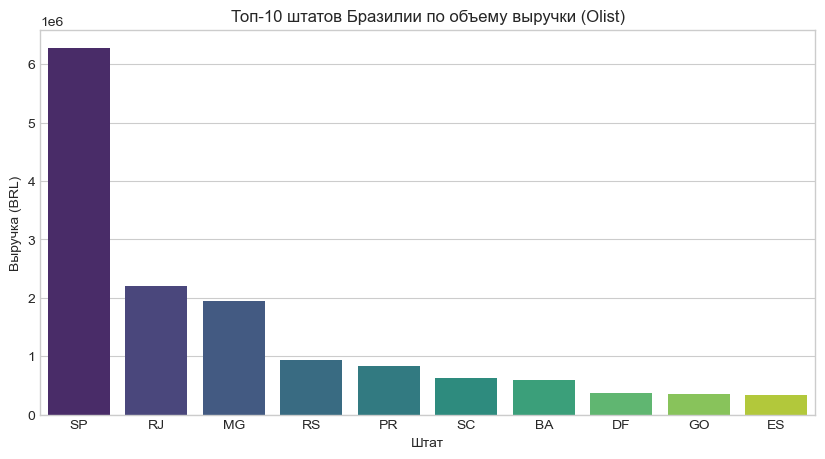

ВЫВОД: Безусловный лидер — штат Сан-Паулу (SP), он генерирует 38.2% всей выручки компании.


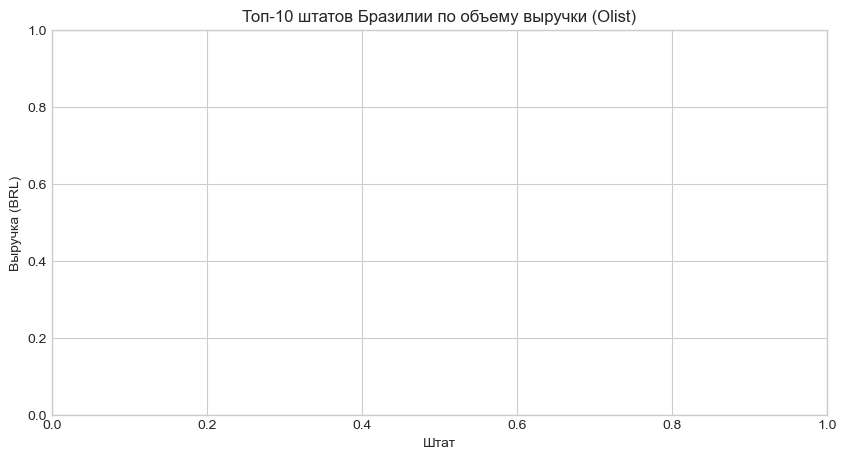

ВЫВОД: Безусловный лидер — штат Сан-Паулу (SP), он генерирует 38.2% всей выручки компании.


In [4]:
top_states = df_clean.groupby('customer_state')['total_revenue'].sum().nlargest(10).reset_index()

top_states = df_clean.groupby('customer_state')['total_revenue'].sum().nlargest(10).reset_index()

sns.barplot(
    data=top_states, 
    x='customer_state', 
    y='total_revenue', 
    hue='customer_state', 
    palette='viridis', 
    legend=False
)
plt.title('Топ-10 штатов Бразилии по объему выручки (Olist)')
plt.xlabel('Штат')
plt.ylabel('Выручка (BRL)')
plt.show()

sp_share = top_states.loc[0, 'total_revenue'] / df_clean['total_revenue'].sum()
print(f"ВЫВОД: Безусловный лидер — штат Сан-Паулу (SP), он генерирует {sp_share:.1%} всей выручки компании.")

plt.title('Топ-10 штатов Бразилии по объему выручки (Olist)')
plt.xlabel('Штат')
plt.ylabel('Выручка (BRL)')
plt.show()

sp_share = top_states.loc[0, 'total_revenue'] / df_clean['total_revenue'].sum()
print(f"ВЫВОД: Безусловный лидер — штат Сан-Паулу (SP), он генерирует {sp_share:.1%} всей выручки компании.")


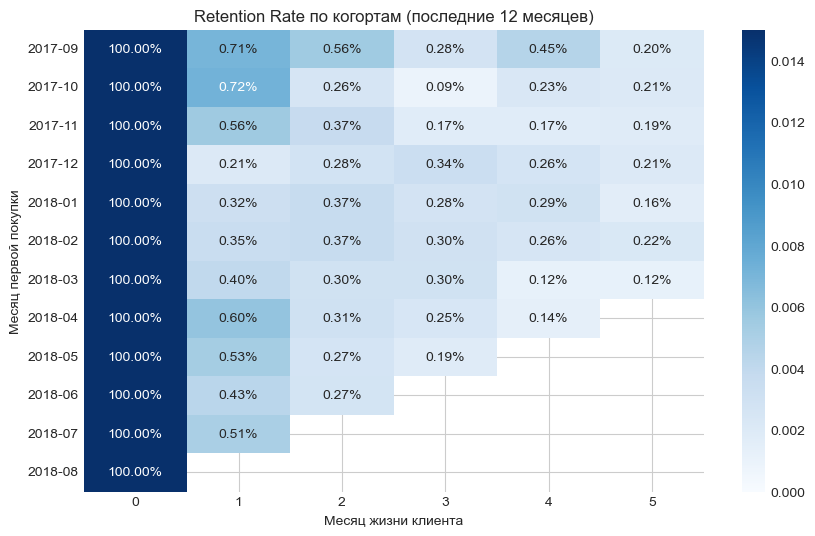

Средний AOV (чек): 171.96 BRL
Средний LTV к 3-му месяцу: 176.42 BRL


In [5]:
# Когортный анализ удержания (Retention Rate)
cohort_counts = df_clean.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().unstack(1)

# Делим на 0-й столбец (размер когорты в первый месяц)
cohort_sizes = cohort_counts.iloc[:, 0]
retention = cohort_counts.divide(cohort_sizes, axis=0)

# Убираем нули и время в датах, чтобы график выглядел аккуратно
retention.index = retention.index.strftime('%Y-%m')

plt.figure(figsize=(10, 6))
sns.heatmap(retention.iloc[-12:, :6], annot=True, fmt='.2%', cmap='Blues', vmin=0, vmax=0.015)
plt.title('Retention Rate по когортам (последние 12 месяцев)')
plt.ylabel('Месяц первой покупки')
plt.xlabel('Месяц жизни клиента')
plt.show()

# Средний LTV за 3-й месяц (индекс столбца 2, так как счет идет с 0)
ltv_cohort = df_clean.groupby(['cohort_month', 'cohort_index'])['total_revenue'].sum().unstack(1).cumsum(axis=1).divide(cohort_sizes, axis=0)
ltv_3m = ltv_cohort[2].mean()

print(f"Средний AOV (чек): {df_clean['total_revenue'].mean():.2f} BRL")
print(f"Средний LTV к 3-му месяцу: {ltv_3m:.2f} BRL")


In [6]:
X = df_clean[['total_freight', 'items_count']]
y = df_clean['total_revenue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
preds = model.predict(X_test)

print(f"Точность модели R2: {r2_score(y_test, preds):.3f}")
print(f"Средняя абсолютная ошибка (MAE): {mean_absolute_error(y_test, preds):.2f} BRL")
print(f"Коэффициенты влияния -> Доставка: +{model.coef_[0]:.2f}, Кол-во товаров: +{model.coef_[1]:.2f}")


Точность модели R2: 0.233
Средняя абсолютная ошибка (MAE): 101.10 BRL
Коэффициенты влияния -> Доставка: +3.75, Кол-во товаров: +36.93


In [7]:
sp_rev = df_clean[df_clean['customer_state'] == 'SP']['total_revenue']
other_rev = df_clean[df_clean['customer_state'] != 'SP']['total_revenue']

stat, p_val = stats.mannwhitneyu(sp_rev, other_rev)
print(f"Медианный чек в SP: {sp_rev.median():.2f} BRL | В остальных штатах: {other_rev.median():.2f} BRL")
print(f"p-value: {p_val:.6f}")

if p_val < 0.05:
    print("ВЫВОД: Различие статистически значимо (отвергаем нулевую гипотезу).")
else:
    print("ВЫВОД: Различие случайно.")

# Сохраняем чистый файл для Power BI
df_clean.to_csv(r'C:\Users\Acer\OneDrive\Desktop\online-shop\data\olist_powerbi_clean.csv', index=False, sep=';', encoding='utf-8-sig')
print("Файл для Power BI успешно сохранен в папку data!")


Медианный чек в SP: 97.64 BRL | В остальных штатах: 116.94 BRL
p-value: 0.000000
ВЫВОД: Различие статистически значимо (отвергаем нулевую гипотезу).
Файл для Power BI успешно сохранен в папку data!
